In [1]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("Danper_Analisis_Exploratorio")
    .getOrCreate()
)

ruta = "hdfs://localhost:9000/danper/gold/produccion_mensual"

df = spark.read.parquet(ruta)

print("===== COLUMNAS DEL DATASET =====")
df.printSchema()

print("\n===== PRIMEROS REGISTROS =====")
df.show(5, truncate=False)

print("\n===== TOTAL DE REGISTROS =====")
print(df.count())

26/10/11 18:24:09 WARN Utils: Your hostname, Debian12 resolves to a loopback address: 127.0.1.1; using 10.0.2.15 instead (on interface enp0s3)
26/10/11 18:24:09 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/11 18:24:10 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
                                                                                

===== COLUMNAS DEL DATASET =====
root
 |-- provincia: string (nullable = true)
 |-- distrito: string (nullable = true)
 |-- cultivo: string (nullable = true)
 |-- periodo: date (nullable = true)
 |-- produccion_t: double (nullable = true)
 |-- precio_chacra_s_kg: double (nullable = true)
 |-- cosechas_ha: double (nullable = true)
 |-- siembras_ha: double (nullable = true)
 |-- superficie_verde_ha: double (nullable = true)
 |-- superficie_perdida_ha: double (nullable = true)
 |-- rendimiento_kg_ha: double (nullable = true)
 |-- anio: integer (nullable = true)
 |-- mes_numero: integer (nullable = true)


===== PRIMEROS REGISTROS =====


+---------+-----------------+---------+----------+------------+------------------+-----------+-----------+-------------------+---------------------+-----------------+----+----------+
|provincia|distrito         |cultivo  |periodo   |produccion_t|precio_chacra_s_kg|cosechas_ha|siembras_ha|superficie_verde_ha|superficie_perdida_ha|rendimiento_kg_ha|anio|mes_numero|
+---------+-----------------+---------+----------+------------+------------------+-----------+-----------+-------------------+---------------------+-----------------+----+----------+
|PACASMAYO|SAN PEDRO DE LLOC|ESPARRAGO|2024-09-01|NULL        |NULL              |NULL       |NULL       |133.0              |NULL                 |NULL             |2024|9         |
|PACASMAYO|SAN PEDRO DE LLOC|ESPARRAGO|2024-10-01|NULL        |NULL              |NULL       |NULL       |133.0              |NULL                 |NULL             |2024|10        |
|PACASMAYO|SAN PEDRO DE LLOC|ESPARRAGO|2024-11-01|NULL        |NULL              |NUL

## 4.1. Análisis exploratorio de datos

### Gráfico 1. Evolución mensual de la producción agrícola

**Pregunta de análisis:** ¿Cómo ha evolucionado la producción agrícola a lo largo de los meses registrados?

**Objetivo:** Identificar las variaciones mensuales del volumen de producción agrícola utilizando los datos de la capa Gold.

**Variables utilizadas:**
- `periodo`: fecha del registro.
- `produccion_t`: producción agrícola expresada en toneladas.

Para evitar distorsiones, se excluyen los registros cuya producción es nula. Los resultados corresponden a los datos disponibles y no necesariamente representan toda la producción de Danper.

===== REGISTROS VALIDOS DE PRODUCCION =====
267

===== PRODUCCION MENSUAL =====
   periodo  produccion_total_t
2025-01-01           26624.958
2025-02-01           23376.030
2025-03-01           15877.510
2025-04-01           12679.690
2025-05-01           13003.670
2025-06-01           14024.470
2025-07-01           19320.560
2025-08-01           40107.108
2025-09-01           62458.619
2025-10-01           64587.028
2025-11-01           61252.779
2025-12-01           27389.689


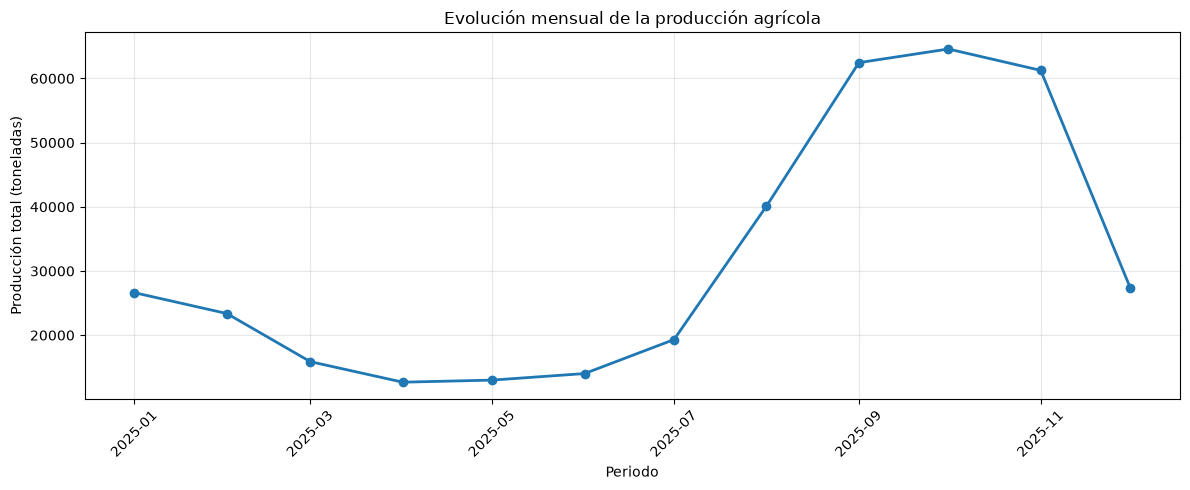

In [2]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

# Excluir registros sin información de producción
df_produccion = df.filter(F.col("produccion_t").isNotNull())

# Agrupar producción por mes
produccion_mensual = (
    df_produccion
    .groupBy("periodo")
    .agg(F.sum("produccion_t").alias("produccion_total_t"))
    .orderBy("periodo")
)

# Convertir los datos agregados a Pandas para graficar
pdf_mensual = produccion_mensual.toPandas()

print("===== REGISTROS VALIDOS DE PRODUCCION =====")
print(df_produccion.count())

print("\n===== PRODUCCION MENSUAL =====")
print(pdf_mensual.to_string(index=False))

# Crear gráfico
plt.figure(figsize=(12, 5))

plt.plot(
    pdf_mensual["periodo"],
    pdf_mensual["produccion_total_t"],
    marker="o",
    linewidth=2
)

plt.title("Evolución mensual de la producción agrícola")
plt.xlabel("Periodo")
plt.ylabel("Producción total (toneladas)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Gráfico 2. Producción agrícola por cultivo

**Pregunta de análisis:** ¿Qué cultivos concentran el mayor volumen de producción agrícola registrada durante 2025?

**Objetivo:** Comparar el volumen total de producción entre cultivos e identificar aquellos con mayor participación en los datos disponibles.

**Variables utilizadas:**
- `cultivo`: tipo de cultivo agrícola.
- `produccion_t`: producción expresada en toneladas.

Se consideran únicamente los registros con valores de producción disponibles.

===== PRODUCCION POR CULTIVO =====
  cultivo  produccion_total_t
 ARANDANO          197208.302
ESPARRAGO          159163.009
ALCACHOFA           24330.800


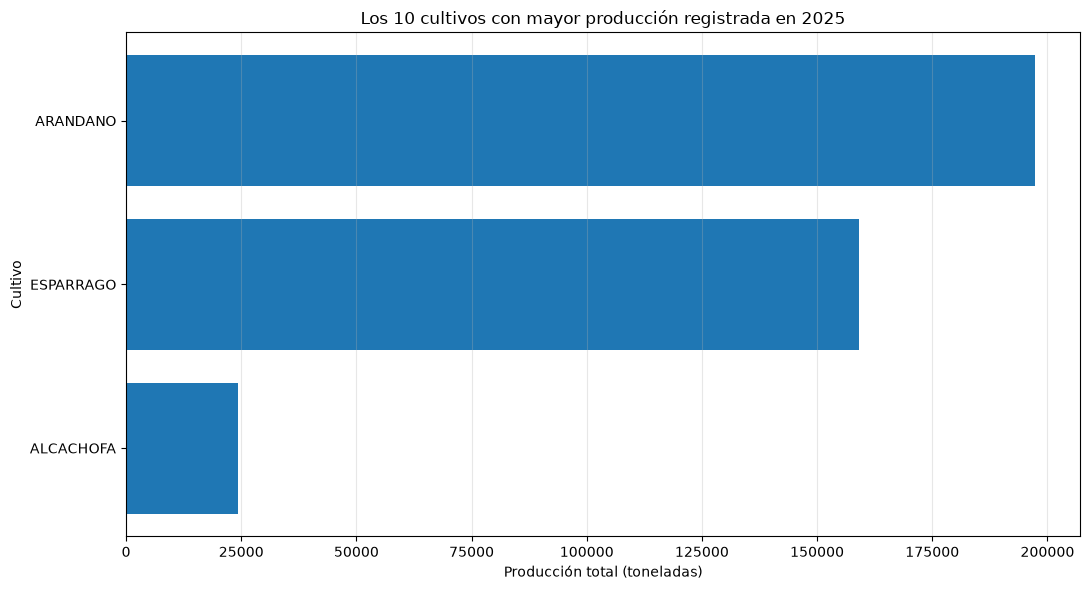

In [3]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

# Agrupar la producción por cultivo
produccion_cultivo = (
    df_produccion
    .filter(F.col("cultivo").isNotNull())
    .groupBy("cultivo")
    .agg(F.sum("produccion_t").alias("produccion_total_t"))
    .orderBy(F.desc("produccion_total_t"))
)

# Convertir los resultados agregados a Pandas
pdf_cultivo = produccion_cultivo.toPandas()

print("===== PRODUCCION POR CULTIVO =====")
print(pdf_cultivo.to_string(index=False))

# Seleccionar los 10 cultivos de mayor producción
top_cultivos = pdf_cultivo.head(10).sort_values("produccion_total_t")

# Crear gráfico
plt.figure(figsize=(11, 6))

plt.barh(
    top_cultivos["cultivo"],
    top_cultivos["produccion_total_t"]
)

plt.title("Los 10 cultivos con mayor producción registrada en 2025")
plt.xlabel("Producción total (toneladas)")
plt.ylabel("Cultivo")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Gráfico 3. Distribución de la producción agrícola por provincia

**Pregunta de análisis:** ¿Qué provincias concentran el mayor volumen de producción agrícola registrada durante 2025?

**Objetivo:** Identificar las provincias con mayor participación en la producción y analizar las diferencias territoriales.

**Variables utilizadas:**
- `provincia`: provincia donde se registra la producción.
- `produccion_t`: producción expresada en toneladas.

Se excluyen los registros con producción nula y se agrupan las toneladas por provincia.

===== PRODUCCION POR PROVINCIA =====
provincia  produccion_total_t
     VIRU          199402.698
   ASCOPE           96081.975
   CHEPEN           54836.899
 TRUJILLO           25352.329
PACASMAYO            5028.210


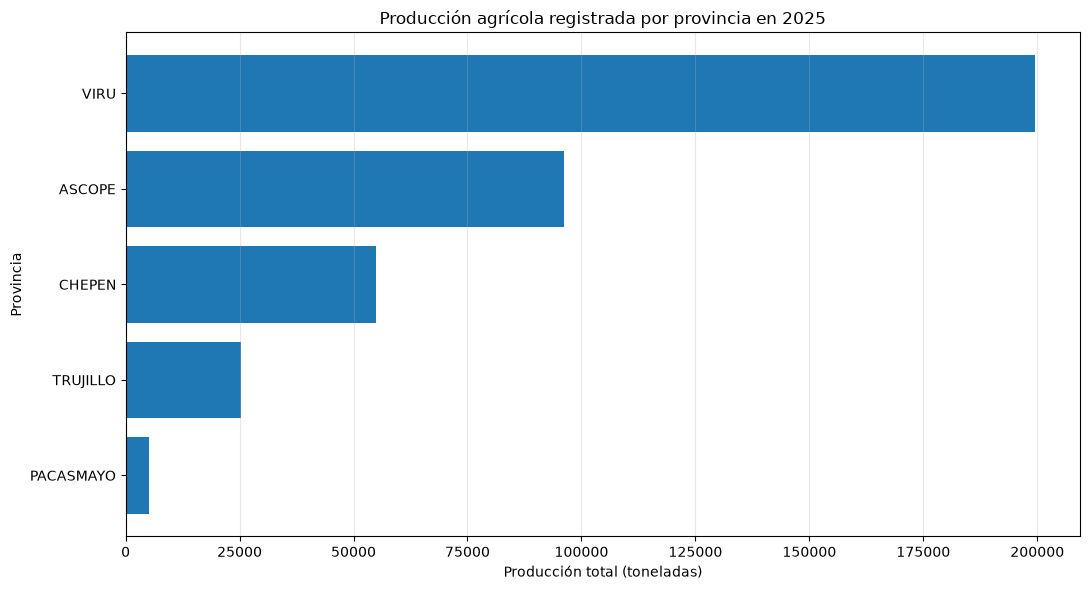

In [4]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

# Agrupar producción por provincia
produccion_provincia = (
    df_produccion
    .filter(F.col("provincia").isNotNull())
    .groupBy("provincia")
    .agg(F.sum("produccion_t").alias("produccion_total_t"))
    .orderBy(F.desc("produccion_total_t"))
)

# Convertir resultados agregados a Pandas
pdf_provincia = produccion_provincia.toPandas()

print("===== PRODUCCION POR PROVINCIA =====")
print(pdf_provincia.to_string(index=False))

# Graficar provincias
grafico = pdf_provincia.sort_values("produccion_total_t")

plt.figure(figsize=(11, 6))

plt.barh(
    grafico["provincia"],
    grafico["produccion_total_t"]
)

plt.title("Producción agrícola registrada por provincia en 2025")
plt.xlabel("Producción total (toneladas)")
plt.ylabel("Provincia")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 4.2. Modelo base

### Propuesta del modelo predictivo

Se propone desarrollar un modelo base de regresión lineal para estimar la producción agrícola registrada, expresada en toneladas, a partir de variables disponibles en la capa Gold.

**Variable objetivo:** `produccion_t`.

**Métrica principal:** error absoluto medio (MAE), expresado en toneladas.

El propósito de este primer modelo es establecer una línea base técnica que permita evaluar posteriormente algoritmos más avanzados.

Antes del entrenamiento se verificará la disponibilidad de datos y se seleccionarán las variables predictoras, evitando utilizar información que pueda revelar directamente el valor objetivo.

In [5]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (
    SparkSession.builder
    .appName("Danper_Modelo_Base")
    .getOrCreate()
)

df = spark.read.parquet(
    "hdfs://localhost:9000/danper/gold/produccion_mensual"
)

print("===== DISPONIBILIDAD DE DATOS =====")

columnas = [
    "produccion_t",
    "cultivo",
    "provincia",
    "distrito",
    "anio",
    "mes_numero",
    "cosechas_ha",
    "siembras_ha",
    "precio_chacra_s_kg",
    "rendimiento_kg_ha"
]

df.select([
    F.count(F.col(c)).alias(c)
    for c in columnas
]).show(vertical=True)

print("\n===== DISTRIBUCION DE REGISTROS VALIDOS POR MES =====")

df.filter(
    F.col("produccion_t").isNotNull()
).groupBy(
    "anio", "mes_numero"
).count().orderBy(
    "anio", "mes_numero"
).show(24)

print("\n===== TOTAL DE REGISTROS =====")
print(df.count())

26/10/11 18:28:39 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


===== DISPONIBILIDAD DE DATOS =====
-RECORD 0-----------------
 produccion_t       | 267 
 cultivo            | 561 
 provincia          | 561 
 distrito           | 561 
 anio               | 561 
 mes_numero         | 561 
 cosechas_ha        | 34  
 siembras_ha        | 36  
 precio_chacra_s_kg | 267 
 rendimiento_kg_ha  | 0   


===== DISTRIBUCION DE REGISTROS VALIDOS POR MES =====


+----+----------+-----+
|anio|mes_numero|count|
+----+----------+-----+
|2025|         1|   28|
|2025|         2|   27|
|2025|         3|   15|
|2025|         4|   13|
|2025|         5|   14|
|2025|         6|   17|
|2025|         7|   16|
|2025|         8|   26|
|2025|         9|   30|
|2025|        10|   27|
|2025|        11|   30|
|2025|        12|   24|
+----+----------+-----+


===== TOTAL DE REGISTROS =====
561


### Entrenamiento y evaluación del modelo base

Se utiliza una regresión lineal para estimar la producción agrícola en toneladas a partir del cultivo, la provincia, el distrito y el mes.

Para respetar el orden temporal de los registros, se emplean los meses de enero a septiembre de 2025 para entrenamiento y los meses de octubre a diciembre para evaluación.

La métrica principal es el error absoluto medio (MAE), que expresa en toneladas la diferencia promedio entre los valores observados y las predicciones.

También se compara el modelo con una referencia sencilla que predice la mediana de producción del conjunto de entrenamiento.

Esta evaluación constituye una línea base técnica inicial y no demuestra todavía la capacidad de generalización a otros años.

In [7]:
%pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 3.1 MB/s  0:00:033.1 MB/s eta 0:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 2.9 MB/s  0:00:12 eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn]0m 5/6 [scikit-learn]]
Note: you may need to restart the kernel to use updated packages.


In [8]:
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Seleccionar los datos disponibles
columnas = [
    "cultivo",
    "provincia",
    "distrito",
    "mes_numero",
    "produccion_t"
]

datos = (
    df.select(*columnas)
    .filter(
        F.col("produccion_t").isNotNull()
        & F.col("mes_numero").isNotNull()
        & F.col("cultivo").isNotNull()
        & F.col("provincia").isNotNull()
        & F.col("distrito").isNotNull()
    )
    .toPandas()
)

# 2. Separación temporal
entrenamiento = datos[datos["mes_numero"] <= 9].copy()
prueba = datos[datos["mes_numero"] >= 10].copy()

variables = [
    "cultivo",
    "provincia",
    "distrito",
    "mes_numero"
]

X_train = entrenamiento[variables]
y_train = entrenamiento["produccion_t"]

X_test = prueba[variables]
y_test = prueba["produccion_t"]

print("===== DISTRIBUCION DE DATOS =====")
print("Registros para entrenamiento:", len(entrenamiento))
print("Registros para prueba:", len(prueba))

# 3. Preparación de variables categóricas
preprocesador = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            ["cultivo", "provincia", "distrito"]
        ),
        (
            "numericas",
            "passthrough",
            ["mes_numero"]
        )
    ]
)

# 4. Modelo de regresión lineal
modelo = Pipeline([
    ("preprocesamiento", preprocesador),
    ("regresion", LinearRegression())
])

modelo.fit(X_train, y_train)

# 5. Predicciones
predicciones = modelo.predict(X_test)

# 6. Métricas
mae = mean_absolute_error(y_test, predicciones)
rmse = np.sqrt(mean_squared_error(y_test, predicciones))
r2 = r2_score(y_test, predicciones)

# 7. Modelo de referencia: mediana
referencia = DummyRegressor(strategy="median")
referencia.fit(X_train, y_train)
pred_referencia = referencia.predict(X_test)

mae_referencia = mean_absolute_error(
    y_test,
    pred_referencia
)

print("\n===== RESULTADOS DEL MODELO BASE =====")
print(f"MAE Regresión Lineal: {mae:.2f} toneladas")
print(f"RMSE Regresión Lineal: {rmse:.2f} toneladas")
print(f"R² Regresión Lineal: {r2:.4f}")

print("\n===== COMPARACION CON REFERENCIA =====")
print(f"MAE Referencia (mediana): {mae_referencia:.2f} toneladas")
print(f"MAE Regresión Lineal: {mae:.2f} toneladas")

if mae < mae_referencia:
    print("La regresión lineal supera a la referencia.")
else:
    print("La regresión lineal no supera a la referencia.")

# 8. Mostrar predicciones de ejemplo
resultados = prueba[
    ["cultivo", "provincia", "distrito", "mes_numero"]
].copy()

resultados["produccion_real_t"] = y_test.to_numpy()
resultados["produccion_predicha_t"] = predicciones

print("\n===== EJEMPLOS DE PREDICCIONES =====")
print(resultados.head(10).to_string(index=False))

===== DISTRIBUCION DE DATOS =====
Registros para entrenamiento: 186
Registros para prueba: 81

===== RESULTADOS DEL MODELO BASE =====
MAE Regresión Lineal: 1868.54 toneladas
RMSE Regresión Lineal: 3086.99 toneladas
R² Regresión Lineal: 0.2989

===== COMPARACION CON REFERENCIA =====
MAE Referencia (mediana): 1745.51 toneladas
MAE Regresión Lineal: 1868.54 toneladas
La regresión lineal no supera a la referencia.

===== EJEMPLOS DE PREDICCIONES =====
  cultivo provincia     distrito  mes_numero  produccion_real_t  produccion_predicha_t
ESPARRAGO PACASMAYO JEQUETEPEQUE          11              42.35             812.085472
ESPARRAGO PACASMAYO JEQUETEPEQUE          12              45.48             944.087912
 ARANDANO PACASMAYO     SAN JOSE          11             598.10            1818.863029
 ARANDANO PACASMAYO     SAN JOSE          12             499.00            1950.865470
 ARANDANO  TRUJILLO       LAREDO          11             269.26             953.961214
ESPARRAGO  TRUJILLO       

### Interpretación de los resultados del modelo base

El modelo de regresión lineal fue entrenado utilizando 186 registros correspondientes a enero-septiembre de 2025 y evaluado con 81 registros de octubre-diciembre del mismo año.

Se obtuvo un error absoluto medio (MAE) de 1 868.54 toneladas, un RMSE de 3 086.99 toneladas y un coeficiente de determinación R² de 0.2989. Estos resultados indican que el modelo presenta una capacidad predictiva limitada, especialmente ante registros con volúmenes de producción muy diferentes.

Al compararlo con un modelo de referencia basado en la mediana de entrenamiento, cuyo MAE fue de 1 745.51 toneladas, se observa que la regresión lineal no logra superar dicha referencia.

Por tanto, se establece un **MAE de 1 868.54 toneladas como línea base técnica de la regresión lineal**, mientras que el MAE de 1 745.51 toneladas constituye el umbral de referencia que los siguientes modelos deberán intentar superar.

### Mejoras previstas

En la siguiente etapa se evaluarán algoritmos capaces de representar relaciones no lineales, como Random Forest, además de explorar nuevas variables predictoras y técnicas de transformación de la variable objetivo.

También se revisará la variabilidad de la producción por cultivo y ubicación, así como la disponibilidad de información histórica adicional, para mejorar la capacidad de generalización del modelo.

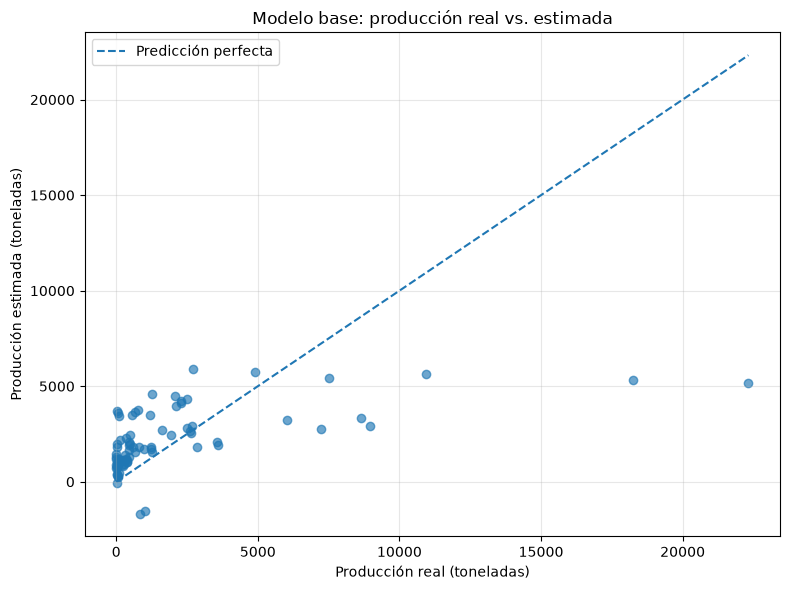

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    predicciones,
    alpha=0.65
)

limite = max(y_test.max(), predicciones.max())

plt.plot(
    [0, limite],
    [0, limite],
    linestyle="--",
    label="Predicción perfecta"
)

plt.title("Modelo base: producción real vs. estimada")
plt.xlabel("Producción real (toneladas)")
plt.ylabel("Producción estimada (toneladas)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretación de las predicciones

El gráfico evidencia diferencias entre los valores reales y las estimaciones del modelo de regresión lineal. Se observa que el modelo tiende a subestimar los registros con mayores volúmenes de producción y presenta algunas predicciones negativas, lo cual constituye una limitación para su aplicación práctica.

Estos resultados confirman la necesidad de mejorar la capacidad predictiva del modelo, incorporando algoritmos no lineales y nuevas variables explicativas.

Por ello, se mantiene el MAE de 1 868.54 toneladas como línea base técnica para las siguientes etapas del proyecto.